In [1]:
#read in 733 sample x 3.5+ million DHS presence/absence matrix
import pandas as pd
import scipy as sp
import numpy as np
from lightfm import cross_validation
from lightfm.evaluation import precision_at_k
from lightfm.evaluation import recall_at_k
from lightfm.evaluation import auc_score
from lightfm import LightFM
import matplotlib.pyplot as plt
import pickle

In [23]:
dhs = pd.read_table('dat_bin_FDR01_hg38.txt.gz', header=None).T
dhs.shape

(733, 3591898)

In [ ]:
data_coo = sp.sparse.coo_matrix(dhs.values)

In [38]:
#splitting data into train and test
(train, test) = cross_validation.random_train_test_split(data_coo, test_percentage=0.2, random_state=None)
data = {'train': train, 'test': test}

In [39]:
#creating model
model_e15_d16 = LightFM(no_components=16, loss='warp')

In [40]:
#training model
model_e15_d16.fit(data['train'], epochs=15, num_threads=2)

In [41]:
pickle_out_model = open('/home/ctrader/Hold/DHS/DHS_model_e15_d16.pickle', 'wb')
pickle.dump(model_e15_d16, pickle_out_model)
pickle_out_model.close()

pickle_out_data = open('/home/ctrader/Hold/DHS/DHS_data_e15_d16.pickle', 'wb')
pickle.dump(data, pickle_out_data)
pickle_out_data.close()

In [33]:
pickle_in = open('/home/ctrader/Hold/DHS/DHS_model_e15_d16.pickle', 'rb')
DHS_model_e15_d16=pickle.load(pickle_in)

pickle_in = open('/home/ctrader/Hold/DHS/DHS_data_e15_d16.pickle', 'rb')
DHS_data_e15_d16=pickle.load(pickle_in)

In [ ]:
# measure precision/recall @ k for k=1:50
# test_precision = []
# test_recall = []
# train_precision = []
# train_recall = []

# for i in [1, 10, 100, 1000, 10000]:
#     test_precision.append(precision_at_k(model30_d1, data['test'], k=i).mean())
#     print('i')
#     test_recall.append(recall_at_k(model30, data['test'], k=i).mean())
#     train_precision.append(precision_at_k(model30, data['train'], k=i).mean())
#     train_recall.append(recall_at_k(model30, data['train'], k=i).mean())
#     print("k=" + i + " Finished")

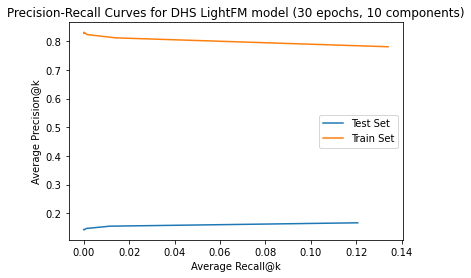

In [19]:
#Plot precision-recall curves for train and test data
plt.plot(test_recall, test_precision)
plt.plot(train_recall, train_precision)
plt.xlabel('Average Recall@k')
plt.ylabel('Average Precision@k')
plt.legend(['Test Set', 'Train Set']) #, 'Train Set'
plt.title('Precision-Recall Curves for DHS LightFM model (30 epochs, 10 components)')
plt.savefig('PR_Curves_DHS_LightFM_CT20211004.jpeg')

In [14]:
item_biases, item_embeddings = model.get_item_representations(features=None)
user_biases, user_embeddings = model.get_user_representations(features=None)

In [13]:
print(item_embeddings.shape)
print(user_embeddings)

(3591898, 10)
[[ 2.594112   -2.7120328   1.3811816  ...  2.0611312  -2.729041
  -3.6168811 ]
 [ 1.4131172   3.722523   -2.1493971  ... -1.370422   -0.6829925
  -1.4827424 ]
 [ 2.2060719  -1.6619732   3.2524655  ...  0.2379665  -2.3723385
  -3.6720824 ]
 ...
 [ 3.6081746   1.5524385   1.6069187  ... -0.9677343  -0.09321057
  -1.9476378 ]
 [ 2.599359    0.3400904   3.399262   ...  1.7615211   2.4782457
  -2.4411473 ]
 [ 2.5906262  -0.39559594  3.5373619  ...  2.1963093   2.1646953
  -2.6249156 ]]


In [ ]:
# auc = auc_score(model, data['test'])

In [5]:
n_biosamples, n_dhs = data['train'].shape

In [22]:
scores = model.predict(24, np.arange(n_dhs))
#rank from most liked to least
top_items = [np.argsort(-scores)][0]
print(top_items[0:3])

[2898345  356003  209678]


In [26]:
tsv_file = open("DHS_Index_and_Vocabulary_metadata.tsv")
df = pd.read_csv(tsv_file, delimiter="\t")
# print(df.head(20))

In [27]:
biosample_df = df[['library order', 'Biosample name']]

In [70]:
print(biosample_df[biosample_df['library order']==1]['Biosample name'][0])
print(biosample_df[biosample_df['Biosample name']=='GM06990']['library order'][0])

GM06990
1


In [29]:
DHS_metadata = pd.read_table('DHS_Index_and_Vocabulary_hg38_WM20190703.txt.gz', header=None)

col_names = DHS_metadata.iloc[0]
DHS_metadata = DHS_metadata[1:]
DHS_metadata.columns = col_names

/home/ctrader/.conda/envs/lightfm/lib/python3.8/site-packages/IPython/core/interactiveshell.py:3441: DtypeWarning: Columns (1,2,3,4,5,6,7,8) have mixed types.Specify dtype option on import or set low_memory=False.
  exec(code_obj, self.user_global_ns, self.user_ns)


In [34]:
#function to recommend DHSs for a given biosample. Takes in the model, data, and a list of
#biosamples for DHSs to be recommend for. For each biosample, prints out known associated DHSs
#and a list of recommended DHSs. Function modeled after tutorial 3, 'Recommendation Systems
#- Learn Python for Data Science' on LightFM github. 

def sample_recommendation(model, data, biosamples, recommend_num=5): #, full_data=gd_coo
    
    #number of biosamples and DHSs in dataset
    n_biosamples, n_DHSs = data['train'].shape
    
    #generate DHS recommendations for each biosample
    for biosample_name in biosamples:
        biosample = list(biosample_df[biosample_df['Biosample name']==biosample_name]['library order'])[0] - 1
        
        #DHSs known to relate to the biosample
        known_positives = [i for i, dhs_pos in enumerate(list(dhs.T[biosample])) if dhs_pos == 1]
        
        #DHSs model predicts that relate to biosample
        scores = model.predict(biosample, np.arange(n_DHSs))

        #rank from most related to least
        top_DHSs = [np.argsort(-scores)][0]
        
        #print results
        print('Biosample: %s (%s)' %(biosample_name, str(biosample)))
        print('   Number of Known DHSs: %s' %(len(known_positives)))
        
        print()
        print('   Recommended DHS Locations:')
        count = 0
        total_count = 0
        for DHS in top_DHSs[:]:
            total_count+=1
            if DHS not in known_positives:
                DHS_metadata_num = DHS+1
                count += 1
                chrom = DHS_metadata.iloc[DHS_metadata_num]['seqname']
                start = DHS_metadata.iloc[DHS_metadata_num]['start']
                end = DHS_metadata.iloc[DHS_metadata_num]['end']
                component = DHS_metadata.iloc[DHS_metadata_num]['component']
                num_samples = DHS_metadata.iloc[DHS_metadata_num]['numsamples']
                print('      %s:%s-%s, Component: %s, Number of Samples: %s' %(chrom, start, end, component, num_samples))
            if count == recommend_num:
                break
                
        print()
        print('Number of known positive recs before 5 new recs: %s' %(total_count))
            
sample_recommendation(DHS_model_e15_d16, DHS_data_e15_d16, ['GM06990'])

Biosample: GM06990 (0)
   Number of Known DHSs: 82918

   Recommended DHS Locations:
      chr10:41860520-41860560, Component: Stromal A, Number of Samples: 1
      chr20:50958880-50959263, Component: Tissue invariant, Number of Samples: 6
      chr6:30557160-30557360, Component: Tissue invariant, Number of Samples: 440
      chr1:86915572-86915800, Component: Tissue invariant, Number of Samples: 396
      chr16:34582405-34582491, Component: Tissue invariant, Number of Samples: 524

Number of known positive recs before 5 new recs: 143


In [35]:
#Precision and Recall @ k scores for DHS_data30.pickle and DHS_model30.pickle
with open('test_precision.txt') as f:
    test_precision = f.readlines()
print(test_precision)
with open('test_recall.txt') as f:
    test_recall = f.readlines()
print(test_recall)

print()
with open('train_precision.txt') as f:
    train_precision = f.readlines()
print(train_precision)
with open('train_recall.txt') as f:
    train_recall = f.readlines()
print(train_recall)

['Test Precision@[1, 10, 100, 1000, 10000] = [0.14324693, 0.14215554, 0.14713506, 0.15518418, 0.16692564]']
['Test Recall@[1, 10, 100, 1000, 10000] = [1.0259158846487058e-05, 0.00010940640060583263, 0.001110367405831415, 0.011533907822787908, 0.1206632319817199]']

['Train Precision@[1, 10, 100, 1000, 10000] = [0.82673943, 0.8308322, 0.8227558, 0.81127965, 0.7803032]']
['Train Recall@[1, 10, 100, 1000, 10000] = [1.4393877337148873e-05, 0.00014346459243132665, 0.001424563018470999, 0.014067948038458017, 0.13405498314124664]']


In [15]:
test_precision = [0.14324693, 0.14215554, 0.14713506, 0.15518418, 0.16692564]
test_recall = [1.0259158846487058e-05, 0.00010940640060583263, 0.001110367405831415, 0.011533907822787908, 0.1206632319817199]

train_precision = [0.82673943, 0.8308322, 0.8227558, 0.81127965, 0.7803032]
train_recall = [1.4393877337148873e-05, 0.00014346459243132665, 0.001424563018470999, 0.014067948038458017, 0.13405498314124664]

In [3]:
train_dense = data['train'].todense()
test_dense = data['test'].todense()

In [24]:
np.squeeze(np.asarray(train_dense[biosample]))

array([0., 0., 0., ..., 0., 0., 0.], dtype=float32)

In [7]:
#Calculating precision and recall for test set
test_precision_list_top = []
test_recall_list_top = []
for k in [1, 10, 100, 1000, 10000]:
    print(k)
    num = []
    n_known_pos = []
    for biosample in range(733):
        if biosample % 100 == 0:
            print(biosample, '/', n_biosamples)
        scores = model.predict(biosample, np.arange(n_dhs)) 
        top_DHSs = [np.argsort(-scores)][0][0:k]
        known_pos = [i for i, dhs_pos in enumerate(np.squeeze(np.asarray(test_dense[biosample]))) if dhs_pos == 1]
        top_in_known = len([i for i in known_pos if i in top_DHSs])
        num.append(top_in_known)
        n_known_pos.append(len(known_pos))
            
    num = np.array(num)
    precision = (num/k).mean()
    recall = (num/n_known_pos).mean()
    print(precision)
    print(recall)
    test_precision_list_top.append(precision)
    test_recall_list_top.append(recall)

1
0 / 733
100 / 733
200 / 733
300 / 733
400 / 733
500 / 733
600 / 733
700 / 733
0.15006821282401092
1.1607047374607913e-05
10
0 / 733
100 / 733
200 / 733
300 / 733
400 / 733
500 / 733
600 / 733
700 / 733
0.1281036834924966
0.00010259687720124615
100
0 / 733
100 / 733
200 / 733
300 / 733
400 / 733
500 / 733
600 / 733
700 / 733
0.13607094133697137
0.0010623306048059748
1000
0 / 733
100 / 733
200 / 733
300 / 733
400 / 733
500 / 733
600 / 733
700 / 733
0.1459781718963165
0.011175172057686316
10000
0 / 733
100 / 733
200 / 733
300 / 733
400 / 733
500 / 733
600 / 733
700 / 733
0.1600350613915416
0.11879437216194183


In [8]:
#Calculating precision and recall for train set
train_precision_list_top = []
train_recall_list_top = []
for k in [1, 10, 100, 1000, 10000]:
    print(k)
    num = []
    n_known_pos = []
    for biosample in range(733):
        if biosample % 100 == 0:
            print(biosample, '/', n_biosamples)
        scores = model.predict(biosample, np.arange(n_dhs)) 
        top_DHSs = [np.argsort(-scores)][0][0:k]
        known_pos = [i for i, dhs_pos in enumerate(np.squeeze(np.asarray(train_dense[biosample]))) if dhs_pos == 1]
        top_in_known = len([i for i in known_pos if i in top_DHSs])
        num.append(top_in_known)
        n_known_pos.append(len(known_pos))
            
    num = np.array(num)
    precision = (num/k).mean()
    recall = (num/n_known_pos).mean()
    print(precision)
    print(recall)
    train_precision_list_top.append(precision)
    train_recall_list_top.append(recall)

1
0 / 733
100 / 733
200 / 733
300 / 733
400 / 733
500 / 733
600 / 733
700 / 733
0.8362892223738063
1.4589387054741919e-05
10
0 / 733
100 / 733
200 / 733
300 / 733
400 / 733
500 / 733
600 / 733
700 / 733
0.8575716234652115
0.000148460313560959
100
0 / 733
100 / 733
200 / 733
300 / 733
400 / 733
500 / 733
600 / 733
700 / 733
0.8448158253751705
0.0014616834782521981
1000
0 / 733
100 / 733
200 / 733
300 / 733
400 / 733
500 / 733
600 / 733
700 / 733
0.8309222373806274
0.014391052828586376
10000
0 / 733
100 / 733
200 / 733
300 / 733
400 / 733
500 / 733
600 / 733
700 / 733
0.7954879945429739
0.13631831128367736


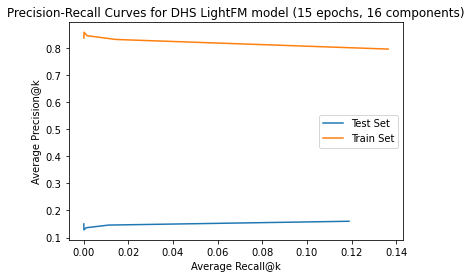

In [18]:
#Plot precision-recall curves for train and test data (15 epochs, 16 dimensions)
plt.plot(test_recall_list_top, test_precision_list_top)
plt.plot(train_recall_list_top, train_precision_list_top)
plt.xlabel('Average Recall@k')
plt.ylabel('Average Precision@k')
plt.legend(['Test Set', 'Train Set']) #, 'Train Set'
plt.title('Precision-Recall Curves for DHS LightFM model (15 epochs, 16 components)')
plt.savefig('PR_Curves_DHS_LightFM_CT20211004.jpeg')

In [20]:
#creating simple model
model_e1_d1 = LightFM(no_components=1, loss='warp')

In [21]:
#training simple model
model_e1_d1.fit(data['train'], epochs=1, num_threads=2)

In [35]:
sample_recommendation(model_e1_d1, data, ['GM06990'])

Biosample: GM06990 (0)
   Number of Known DHSs: 82918

   Recommended DHS Locations:
      chr3:16601580-16601800, Component: Neural, Number of Samples: 2
      chr10:28432440-28432502, Component: Tissue invariant, Number of Samples: 1
      chr15:30626380-30626560, Component: Stromal B, Number of Samples: 277
      chr17:61839568-61839657, Component: Pulmonary devel., Number of Samples: 1
      chr3:52288517-52288726, Component: Placental / trophoblast, Number of Samples: 4

Number of known positive recs before 5 new recs: 75


In [38]:
train_dense = data['train'].todense()
test_dense = data['test'].todense()

In [42]:
#Function for calculating precision and recall
def precision_recall(dense, model, k_vals=[1, 10, 100, 1000, 10000]):
    precision_list_top = []
    recall_list_top = []
    for k in k_vals:
        print('k = ' + str(k))
        num = []
        n_known_pos = []
        for biosample in range(733):
            if biosample % 100 == 0:
                print(biosample, '/', n_biosamples, 'biosamples done')
            scores = model.predict(biosample, np.arange(n_dhs)) 
            top_DHSs = [np.argsort(-scores)][0][0:k]
            known_pos = [i for i, dhs_pos in enumerate(np.squeeze(np.asarray(dense[biosample]))) if dhs_pos == 1]
            top_in_known = len([i for i in known_pos if i in top_DHSs])
            num.append(top_in_known)
            n_known_pos.append(len(known_pos))
            
        num = np.array(num)
        precision = (num/k).mean()
        recall = (num/n_known_pos).mean()
        print('precision@%s = %s' %(k, precision))
        print('recall@%s = %s' %(k, recall))
        precision_list_top.append(precision)
        recall_list_top.append(recall)
    return precision_list_top, recall_list_top

In [43]:
test_precision_e1_d1, test_recall_e1_d1 = precision_recall(test_dense, model_e1_d1)

k = 1
0 / 733 biosamples done
100 / 733 biosamples done
200 / 733 biosamples done
300 / 733 biosamples done
400 / 733 biosamples done
500 / 733 biosamples done
600 / 733 biosamples done
700 / 733 biosamples done
precision@1 = 0.1937244201909959
recall@1 = 1.3154694509024866e-05
k = 10
0 / 733 biosamples done
100 / 733 biosamples done
200 / 733 biosamples done
300 / 733 biosamples done
400 / 733 biosamples done
500 / 733 biosamples done
600 / 733 biosamples done
700 / 733 biosamples done
precision@10 = 0.19276944065484314
recall@10 = 0.0001351832908074869
k = 100
0 / 733 biosamples done
100 / 733 biosamples done
200 / 733 biosamples done
300 / 733 biosamples done
400 / 733 biosamples done
500 / 733 biosamples done
600 / 733 biosamples done
700 / 733 biosamples done
precision@100 = 0.19395634379263305
recall@100 = 0.0013733302147636588
k = 1000
0 / 733 biosamples done
100 / 733 biosamples done
200 / 733 biosamples done
300 / 733 biosamples done
400 / 733 biosamples done
500 / 733 biosamp

In [ ]:
train_precision_e1_d1, train_recall_e1_d1 = precision_recall(train_dense, model_e1_d1)

k = 1
0 / 733 biosamples done


In [18]:
#Precision for random recs
from random import sample
precision_list = []
for k in [1, 10, 100, 1000, 10000]:
    print(k)
    num = []
    for biosample in range(733):
        known_pos = [i for i, dhs_pos in enumerate(np.squeeze(np.asarray(train_dense[biosample]))) if dhs_pos == 1]
        rand_list = sample(range(0, n_dhs), k)
        rand_in_known = len([i for i in known_pos if i in rand_list])
        num.append(rand_in_known)
            
    num = np.array(num)
    precision = (num/k).mean()
    print(precision)
    precision_list.append(precision)

1


KeyboardInterrupt: 